### Motor de Ajedrez Estilo Deep Blue (IA Clásica)

**Objetivo:** Construir un motor de ajedrez basado en búsqueda heurística y teoría de juegos para comprender el mecanismo interno de **IBM Deep Blue** (evaluación estática + árbol de búsqueda Minimax con poda Alfa-Beta).

#### Arquitectura del Proyecto
1. **Representación del estado:** Tablero y reglas legales mediante `python-chess`.
2. **Función de evaluación estática $f(s)$:** Cuantificación numérica de una posición.
3. **Motor de búsqueda:** Algoritmo Minimax con poda Alfa-Beta.
4. **Optimizaciones:** Tablas de posición (PST), *Quiescence Search* y *Zobrist Hashing*.

## 1. Configuración del Entorno
Instalamos `python-chess`, una librería que gestiona las reglas legales del ajedrez (movimientos válidos, enroques, jaques, captura al paso) y permite renderizar el tablero en formato SVG. Esto nos permite enfocarnos directamente en el algoritmo de decisión del motor.

In [ ]:
!pip install python-chess

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 14.5 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for chess: filename=chess-1.11.2-py3-none-any.whl size=147878 sha256=28cb62685223a27fab07411bd4225eb5b9bf869827f4548da048035990cb5824
  Stored in directory: /root/.cache/pip/wheels/74/65/99/8c3a88ba852c1ed8d34daed144b8cb4c654d638677483d19ff
Successfully built chess
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [python-chess]


## 2. Representación del Estado (El Tablero)
En inteligencia artificial clásica, el tablero representa el **estado actual ($s$)** del entorno. Inicializamos una partida estándar y utilizamos el motor gráfico SVG de la librería para inspeccionar visualmente cada estado en el cuaderno.

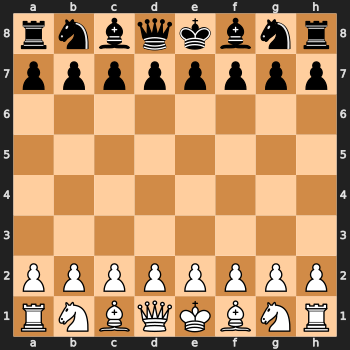

In [ ]:
import chess
import chess.svg
from IPython.display import display, SVG

# Creamos el tablero en la posición inicial
board = chess.Board()

# Mostramos el tablero visualmente (size ajusta el tamaño en píxeles)
display(SVG(chess.svg.board(board, size=350)))

## 3. Función de Evaluación Estática $f(s)$ — Nivel 1: Material
Dado que el árbol completo del ajedrez es computacionalmente imposible de calcular hasta el final ($\approx 10^{120}$ estados posibles), el motor debe detener su búsqueda a cierta profundidad y asignar un valor numérico a la posición.

En esta primera versión, evaluamos únicamente el **balance de material** medido en **centipeones** (1 peón = 100 puntos):
* **Puntuación $> 0$:** Ventaja para las blancas (jugador maximizador).
* **Puntuación $< 0$:** Ventaja para las negras (jugador minimizador).
* **Puntuación $= 0$:** Posición equilibrada o tablas.

In [ ]:
# Valores estándar de las piezas (en centipeones: 1 peón = 100)
VALORES_PIEZAS = {
    chess.PAWN: 100,
    chess.KNIGHT: 320,
    chess.BISHOP: 330,
    chess.ROOK: 500,
    chess.QUEEN: 900,
    chess.KING: 20000
}

def evaluar_tablero(board):
    # Si la partida terminó en jaque mate, devolvemos un valor extremo
    if board.is_checkmate():
        return -99999 if board.turn == chess.WHITE else 99999
    # Si es tablas (ahogado, material insuficiente, etc.), vale 0
    if board.is_stalemate() or board.is_insufficient_material():
        return 0

    puntuacion = 0
    for casilla in chess.SQUARES:
        pieza = board.piece_at(casilla)
        if pieza is not None:
            valor = VALORES_PIEZAS[pieza.piece_type]
            if pieza.color == chess.WHITE:
                puntuacion += valor
            else:
                puntuacion -= valor

    return puntuacion

# Probamos la función en el tablero inicial (debe dar 0)
print("Evaluación inicial:", evaluar_tablero(board))

Evaluación inicial: 0


## 4. El Motor de Búsqueda: Minimax con Poda Alfa-Beta
Con la función de evaluación lista, el motor necesita proyectar jugadas futuras construyendo un **árbol de decisión**:

1. **Minimax:** Es un algoritmo recursivo que alterna turnos simulando el juego perfecto.
   * **Blancas (Maximizador):** Buscan el movimiento que genere la puntuación más alta.
   * **Negras (Minimizador):** Buscan el movimiento que genere la puntuación más baja.
2. **Poda Alfa-Beta ($\alpha-\beta$):** Optimización matemática que elimina ramas inútiles del árbol sin alterar el resultado final.
   * **$\alpha$ (Alfa):** La mejor puntuación garantizada hasta ahora para las blancas.
   * **$\beta$ (Beta):** La mejor puntuación garantizada hasta ahora para las negras.
   * **Condición de corte ($\beta \le \alpha$):** Si en una rama el oponente ya tiene una respuesta mejor que la que podemos forzar en otra rama previa, dejamos de explorar esa rama inmediatamente.

Agregamos además un contador global (`nodos_evaluados`) para medir el costo computacional de cada búsqueda.

In [ ]:
import time

# Contador para medir cuántas posiciones evalúa el motor
nodos_evaluados = 0

def minimax_alfa_beta(board, profundidad, alfa, beta, es_maximizador):
    global nodos_evaluados
    nodos_evaluados += 1

    # Caso base: llegamos al límite de profundidad o la partida terminó
    if profundidad == 0 or board.is_game_over():
        return evaluar_tablero(board)

    if es_maximizador:
        mejor_valor = -float('inf')
        for jugada in board.legal_moves:
            board.push(jugada)  # Simular jugada
            valor = minimax_alfa_beta(board, profundidad - 1, alfa, beta, False)
            board.pop()         # Deshacer jugada (backtracking)

            mejor_valor = max(mejor_valor, valor)
            alfa = max(alfa, mejor_valor)
            if beta <= alfa:
                break  # Poda Beta
        return mejor_valor
    else:
        mejor_valor = float('inf')
        for jugada in board.legal_moves:
            board.push(jugada)  # Simular jugada
            valor = minimax_alfa_beta(board, profundidad - 1, alfa, beta, True)
            board.pop()         # Deshacer jugada (backtracking)

            mejor_valor = min(mejor_valor, valor)
            beta = min(beta, mejor_valor)
            if beta <= alfa:
                break  # Poda Alfa
        return mejor_valor

## 5. Ejecución del Motor: Elegir la Mejor Jugada
La función `buscar_mejor_jugada` recorre todos los movimientos legales en la raíz del árbol, llama a `minimax_alfa_beta` para cada uno y selecciona el que devuelve la mejor puntuación según el turno actual.

Para probarlo de forma realista, cargaremos una posición táctica mediante un código **FEN** (donde hay una captura ventajosa disponible) y renderizaremos la decisión del motor con una flecha verde sobre el tablero.

Mejor jugada: c4b5 | Evaluación: 100 | Nodos: 1854 | Tiempo: 0.13s


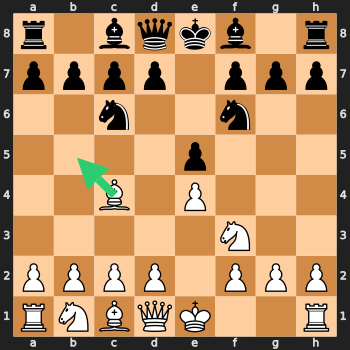

In [ ]:
def buscar_mejor_jugada(board, profundidad):
    global nodos_evaluados
    nodos_evaluados = 0
    inicio = time.time()

    es_blancas = (board.turn == chess.WHITE)
    mejor_jugada = None
    mejor_valor = -float('inf') if es_blancas else float('inf')

    alfa = -float('inf')
    beta = float('inf')

    for jugada in board.legal_moves:
        board.push(jugada)
        valor = minimax_alfa_beta(board, profundidad - 1, alfa, beta, not es_blancas)
        board.pop()

        if es_blancas:
            if valor > mejor_valor:
                mejor_valor = valor
                mejor_jugada = jugada
            alfa = max(alfa, mejor_valor)
        else:
            if valor < mejor_valor:
                mejor_valor = valor
                mejor_jugada = jugada
            beta = min(beta, mejor_valor)

    tiempo = time.time() - inicio
    print(f"Mejor jugada: {mejor_jugada} | Evaluación: {mejor_valor} | Nodos: {nodos_evaluados} | Tiempo: {tiempo:.2f}s")
    return mejor_jugada

# Posición de prueba (FEN): Turno de las blancas, pueden ganar material tácticamente
board_test = chess.Board("r1bqkb1r/pppp1ppp/2n2n2/4p3/2B1P3/5N2/PPPP1PPP/RNBQK2R w KQkq - 4 4")

# Ejecutamos la búsqueda a profundidad 3
jugada_elegida = buscar_mejor_jugada(board_test, profundidad=3)

# Dibujamos el tablero con una flecha indicando la jugada calculada
flecha = [chess.svg.Arrow(jugada_elegida.from_square, jugada_elegida.to_square, color="#2ecc71")]
display(SVG(chess.svg.board(board_test, arrows=flecha, size=350)))

## 6. Función de Evaluación Nivel 2: Piece-Square Tables (PST)
En ajedrez, el valor de una pieza depende de dónde esté ubicada:
* Un **caballo** en el centro controla 8 casillas; en una esquina, solo 2.
* Los **peones** centrales avanzados dominan el espacio y facilitan el desarrollo.
* El **rey** debe resguardarse en los flancos (enroque) durante el medio juego.

Para modelar esto sin usar redes neuronales, los motores clásicos como Deep Blue utilizan **Piece-Square Tables (PST)**: matrices de 8x8 que asignan bonificaciones o penalizaciones (en centipeones) a cada casilla.

La función de evaluación ahora combina dos términos:
$$f(s) = \text{Material} + \text{Posición (PST)}$$

> **Nota técnica:** En `python-chess`, la casilla `0` es `a1` (abajo a la izquierda). Como escribimos las tablas visualmente desde la fila 8 hacia la fila 1, usamos `chess.square_mirror(casilla)` para alinear las piezas blancas y el índice directo para las negras (simetría vertical).

In [ ]:
# Tablas PST (escritas desde la perspectiva de las blancas: fila 8 arriba, fila 1 abajo)
PST_PAWN = [
     0,  0,  0,  0,  0,  0,  0,  0,
    50, 50, 50, 50, 50, 50, 50, 50,
    10, 10, 20, 30, 30, 20, 10, 10,
     5,  5, 10, 25, 25, 10,  5,  5,
     0,  0,  0, 20, 20,  0,  0,  0,
     5, -5,-10,  0,  0,-10, -5,  5,
     5, 10, 10,-20,-20, 10, 10,  5,
     0,  0,  0,  0,  0,  0,  0,  0
]

PST_KNIGHT = [
   -50,-40,-30,-30,-30,-30,-40,-50,
   -40,-20,  0,  0,  0,  0,-20,-40,
   -30,  0, 10, 15, 15, 10,  0,-30,
   -30,  5, 15, 20, 20, 15,  5,-30,
   -30,  0, 15, 20, 20, 15,  0,-30,
   -30,  5, 10, 15, 15, 10,  5,-30,
   -40,-20,  0,  5,  5,  0,-20,-40,
   -50,-40,-30,-30,-30,-30,-40,-50
]

PST_BISHOP = [
   -20,-10,-10,-10,-10,-10,-10,-20,
   -10,  0,  0,  0,  0,  0,  0,-10,
   -10,  0,  5, 10, 10,  5,  0,-10,
   -10,  5,  5, 10, 10,  5,  5,-10,
   -10,  0, 10, 10, 10, 10,  0,-10,
   -10, 10, 10, 10, 10, 10, 10,-10,
   -10,  5,  0,  0,  0,  0,  5,-10,
   -20,-10,-10,-10,-10,-10,-10,-20
]

PST_ROOK = [
     0,  0,  0,  0,  0,  0,  0,  0,
     5, 10, 10, 10, 10, 10, 10,  5,
    -5,  0,  0,  0,  0,  0,  0, -5,
    -5,  0,  0,  0,  0,  0,  0, -5,
    -5,  0,  0,  0,  0,  0,  0, -5,
    -5,  0,  0,  0,  0,  0,  0, -5,
    -5,  0,  0,  0,  0,  0,  0, -5,
     0,  0,  0,  5,  5,  0,  0,  0
]

PST_QUEEN = [
   -20,-10,-10, -5, -5,-10,-10,-20,
   -10,  0,  0,  0,  0,  0,  0,-10,
   -10,  0,  5,  5,  5,  5,  0,-10,
    -5,  0,  5,  5,  5,  5,  0, -5,
     0,  0,  5,  5,  5,  5,  0, -5,
   -10,  5,  5,  5,  5,  5,  0,-10,
   -10,  0,  5,  0,  0,  0,  0,-10,
   -20,-10,-10, -5, -5,-10,-10,-20
]

PST_KING = [
   -30,-40,-40,-50,-50,-40,-40,-30,
   -30,-40,-40,-50,-50,-40,-40,-30,
   -30,-40,-40,-50,-50,-40,-40,-30,
   -30,-40,-40,-50,-50,-40,-40,-30,
   -20,-30,-30,-40,-40,-30,-30,-20,
   -10,-20,-20,-20,-20,-20,-20,-10,
    20, 20,  0,  0,  0,  0, 20, 20,
    20, 30, 10,  0,  0, 10, 30, 20
]

TABLAS_PST = {
    chess.PAWN: PST_PAWN,
    chess.KNIGHT: PST_KNIGHT,
    chess.BISHOP: PST_BISHOP,
    chess.ROOK: PST_ROOK,
    chess.QUEEN: PST_QUEEN,
    chess.KING: PST_KING
}

# Sobrescribimos evaluar_tablero para incluir las PST
def evaluar_tablero(board):
    if board.is_checkmate():
        return -99999 if board.turn == chess.WHITE else 99999
    if board.is_stalemate() or board.is_insufficient_material():
        return 0

    puntuacion = 0
    for casilla in chess.SQUARES:
        pieza = board.piece_at(casilla)
        if pieza is not None:
            valor_material = VALORES_PIEZAS[pieza.piece_type]
            tabla = TABLAS_PST[pieza.piece_type]

            if pieza.color == chess.WHITE:
                valor_posicional = tabla[chess.square_mirror(casilla)]
                puntuacion += (valor_material + valor_posicional)
            else:
                valor_posicional = tabla[casilla]
                puntuacion -= (valor_material + valor_posicional)

    return puntuacion

## 7. Prueba con Evaluación Posicional
Ejecutamos nuevamente `buscar_mejor_jugada` sobre la misma posición de prueba (y sobre el tablero inicial) para observar cómo el motor ahora prioriza el desarrollo de piezas, el control del centro o el enroque en lugar de hacer jugadas arbitrarias.

Mejor jugada: g1f3 | Evaluación: 50 | Nodos: 777 | Tiempo: 0.05s


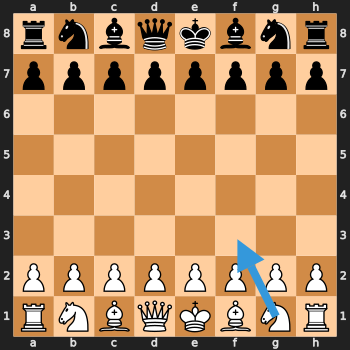

Mejor jugada: b1c3 | Evaluación: 110 | Nodos: 3019 | Tiempo: 0.29s


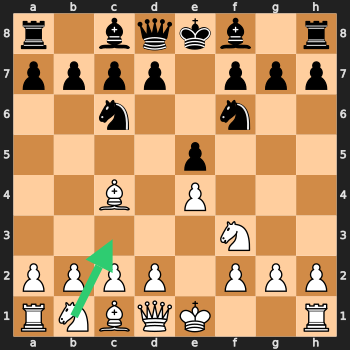

In [ ]:
# 1. Prueba desde la posición inicial de una partida
board_inicio = chess.Board()
jugada_apertura = buscar_mejor_jugada(board_inicio, profundidad=3)
flecha_inicio = [chess.svg.Arrow(jugada_apertura.from_square, jugada_apertura.to_square, color="#3498db")]
display(SVG(chess.svg.board(board_inicio, arrows=flecha_inicio, size=350)))

# 2. Prueba en la misma posición FEN del Bloque 5
jugada_pst = buscar_mejor_jugada(board_test, profundidad=3)
flecha_pst = [chess.svg.Arrow(jugada_pst.from_square, jugada_pst.to_square, color="#2ecc71")]
display(SVG(chess.svg.board(board_test, arrows=flecha_pst, size=350)))

## 8. Optimización de Búsqueda: Ordenamiento de Movimientos (MVV-LVA)
La eficiencia de la **Poda Alfa-Beta** depende drásticamente del orden en que se exploran las jugadas:
* Si evaluamos primero las peores jugadas, el algoritmo apenas puede podar ramas.
* Si evaluamos primero las mejores jugadas (como capturas ventajosas o promociones), los límites $\alpha$ y $\beta$ se estrechan de inmediato y se descartan miles de posiciones irrelevantes.

Para lograr esto usamos la heurística **MVV-LVA** (*Most Valuable Victim - Least Valuable Aggressor*):
$$\text{Prioridad} = (10 \times \text{Valor de la Víctima}) - \text{Valor del Atacante}$$

*Ejemplo:* Capturar una Dama con un Peón ($10 \times 900 - 100 = 8900$) se evalúa mucho antes que capturar un Peón con una Dama ($10 \times 100 - 900 = 100$).

In [ ]:
def puntuar_jugada(board, jugada):
    puntuacion = 0

    # 1. Priorizar capturas usando MVV-LVA
    if board.is_capture(jugada):
        pieza_atacante = board.piece_at(jugada.from_square)
        pieza_victima = board.piece_at(jugada.to_square)

        valor_atacante = VALORES_PIEZAS[pieza_atacante.piece_type] if pieza_atacante else 0
        # En captura al paso (en passant), to_square está vacía pero se captura un peón
        valor_victima = VALORES_PIEZAS[pieza_victima.piece_type] if pieza_victima else VALORES_PIEZAS[chess.PAWN]

        puntuacion += 10 * valor_victima - valor_atacante

    # 2. Priorizar promociones de peón
    if jugada.promotion:
        puntuacion += VALORES_PIEZAS[jugada.promotion]

    return puntuacion

def obtener_jugadas_ordenadas(board):
    return sorted(board.legal_moves, key=lambda j: puntuar_jugada(board, j), reverse=True)

# Actualizamos minimax_alfa_beta para usar las jugadas ordenadas
def minimax_alfa_beta_ordenado(board, profundidad, alfa, beta, es_maximizador):
    global nodos_evaluados
    nodos_evaluados += 1

    if profundidad == 0 or board.is_game_over():
        return evaluar_tablero(board)

    jugadas = obtener_jugadas_ordenadas(board)

    if es_maximizador:
        mejor_valor = -float('inf')
        for jugada in jugadas:
            board.push(jugada)
            valor = minimax_alfa_beta_ordenado(board, profundidad - 1, alfa, beta, False)
            board.pop()

            mejor_valor = max(mejor_valor, valor)
            alfa = max(alfa, mejor_valor)
            if beta <= alfa:
                break
        return mejor_valor
    else:
        mejor_valor = float('inf')
        for jugada in jugadas:
            board.push(jugada)
            valor = minimax_alfa_beta_ordenado(board, profundidad - 1, alfa, beta, True)
            board.pop()

            mejor_valor = min(mejor_valor, valor)
            beta = min(beta, mejor_valor)
            if beta <= alfa:
                break
        return mejor_valor

## 9. Experimento Comparativo: Impacto del Ordenamiento en la Poda
Comparamos ambas versiones sobre una posición de medio juego compleja a **profundidad 4**. Ambas deben devolver **exactamente la misma jugada y la misma evaluación matemática**, pero la versión con MVV-LVA debería explorar una fracción de los nodos en mucho menos tiempo.

In [ ]:
def buscar_mejor_jugada_optimizada(board, profundidad):
    global nodos_evaluados
    nodos_evaluados = 0
    inicio = time.time()

    es_blancas = (board.turn == chess.WHITE)
    mejor_jugada = None
    mejor_valor = -float('inf') if es_blancas else float('inf')

    alfa = -float('inf')
    beta = float('inf')

    for jugada in obtener_jugadas_ordenadas(board):
        board.push(jugada)
        valor = minimax_alfa_beta_ordenado(board, profundidad - 1, alfa, beta, not es_blancas)
        board.pop()

        if es_blancas:
            if valor > mejor_valor:
                mejor_valor = valor
                mejor_jugada = jugada
            alfa = max(alfa, mejor_valor)
        else:
            if valor < mejor_valor:
                mejor_valor = valor
                mejor_jugada = jugada
            beta = min(beta, mejor_valor)

    tiempo = time.time() - inicio
    print(f"[CON MVV-LVA] Mejor jugada: {mejor_jugada} | Eval: {mejor_valor} | Nodos: {nodos_evaluados} | Tiempo: {tiempo:.2f}s")
    return mejor_jugada

# Posición de medio juego con múltiples tensiones tácticas
board_medio_juego = chess.Board("r2q1rk1/ppp2ppp/2np1n2/2b1p1B1/2B1P1b1/2NP1N2/PPP2PPP/R2Q1RK1 w - - 4 8")

print("--- Comparación a profundidad 4 ---")
buscar_mejor_jugada(board_medio_juego, profundidad=4)
buscar_mejor_jugada_optimizada(board_medio_juego, profundidad=4)

--- Comparación a profundidad 4 ---
Mejor jugada: c4b3 | Evaluación: -115 | Nodos: 126126 | Tiempo: 10.22s
[CON MVV-LVA] Mejor jugada: c4b3 | Eval: -115 | Nodos: 10286 | Tiempo: 0.85s


Move.from_uci('c4b3')

## 10. Eliminando el Efecto Horizonte: Quiescence Search
Un problema clásico del algoritmo Minimax de profundidad fija es el **efecto horizonte**: si la búsqueda se detiene en `profundidad = 0` justo después de que tu Dama captura un peón, la evaluación estática creerá que ganaste material, sin ver que en la siguiente jugada el oponente captura tu Dama.

**Solución (*Quiescence Search*):**
Cuando `profundidad == 0`, en lugar de devolver `evaluar_tablero(board)` inmediatamente, extendemos la búsqueda **evaluando únicamente capturas** (ordenadas con MVV-LVA) hasta alcanzar una posición "tranquila" (*quiet*).

* **Stand Pat (Evaluación base):** Como en ajedrez normalmente no estás obligado a capturar si ya tienes una buena posición, primero calculamos la puntuación estática actual (`stand_pat`). Si ya supera los límites $\alpha$ o $\beta$, cortamos la rama de inmediato.

In [ ]:
def obtener_capturas_ordenadas(board):
    capturas = [j for j in board.legal_moves if board.is_capture(j)]
    return sorted(capturas, key=lambda j: puntuar_jugada(board, j), reverse=True)

def quiescence_search(board, alfa, beta, es_maximizador):
    global nodos_evaluados
    nodos_evaluados += 1

    # Evaluación estática actual ("stand pat")
    stand_pat = evaluar_tablero(board)

    if es_maximizador:
        if stand_pat >= beta:
            return beta
        if alfa < stand_pat:
            alfa = stand_pat

        for jugada in obtener_capturas_ordenadas(board):
            board.push(jugada)
            valor = quiescence_search(board, alfa, beta, False)
            board.pop()

            if valor >= beta:
                return beta
            if valor > alfa:
                alfa = valor
        return alfa
    else:
        if stand_pat <= alfa:
            return alfa
        if beta > stand_pat:
            beta = stand_pat

        for jugada in obtener_capturas_ordenadas(board):
            board.push(jugada)
            valor = quiescence_search(board, alfa, beta, True)
            board.pop()

            if valor <= alfa:
                return alfa
            if valor < beta:
                beta = valor
        return beta

# Integración: Minimax + Alfa-Beta + MVV-LVA + Quiescence Search
def minimax_completo(board, profundidad, alfa, beta, es_maximizador):
    global nodos_evaluados

    if board.is_game_over():
        nodos_evaluados += 1
        return evaluar_tablero(board)

    # En lugar de cortar en seco en profundidad 0, llamamos a Quiescence Search
    if profundidad == 0:
        return quiescence_search(board, alfa, beta, es_maximizador)

    nodos_evaluados += 1
    jugadas = obtener_jugadas_ordenadas(board)

    if es_maximizador:
        mejor_valor = -float('inf')
        for jugada in jugadas:
            board.push(jugada)
            valor = minimax_completo(board, profundidad - 1, alfa, beta, False)
            board.pop()

            mejor_valor = max(mejor_valor, valor)
            alfa = max(alfa, mejor_valor)
            if beta <= alfa:
                break
        return mejor_valor
    else:
        mejor_valor = float('inf')
        for jugada in jugadas:
            board.push(jugada)
            valor = minimax_completo(board, profundidad - 1, alfa, beta, True)
            board.pop()

            mejor_valor = min(mejor_valor, valor)
            beta = min(beta, mejor_valor)
            if beta <= alfa:
                break
        return mejor_valor

## 11. Experimento: El Efecto Horizonte en Acción
Probamos ambos motores a **profundidad 1** en una trampa táctica simple: la Dama blanca (`d4`) puede capturar un peón negro (`d5`) que está defendido por otro peón (`e6`).
* **Sin Quiescence:** El motor se detiene tras `Qxd5`, cree que ganó un peón gratis y regala la Dama.
* **Con Quiescence:** El motor extiende el cálculo de capturas, ve `exd5` y evita el error fatal.

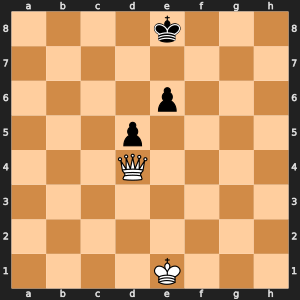

--- Comparación a profundidad 1 ---
[CON MVV-LVA] Mejor jugada: d4d5 | Eval: 805 | Nodos: 29 | Tiempo: 0.00s
[CON QUIESCENCE] Mejor jugada: e1f1 | Eval: 695 | Nodos: 30 | Tiempo: 0.00s


Move.from_uci('e1f1')

In [ ]:
def buscar_mejor_jugada_completa(board, profundidad):
    global nodos_evaluados
    nodos_evaluados = 0
    inicio = time.time()

    es_blancas = (board.turn == chess.WHITE)
    mejor_jugada = None
    mejor_valor = -float('inf') if es_blancas else float('inf')

    alfa = -float('inf')
    beta = float('inf')

    for jugada in obtener_jugadas_ordenadas(board):
        board.push(jugada)
        valor = minimax_completo(board, profundidad - 1, alfa, beta, not es_blancas)
        board.pop()

        if es_blancas:
            if valor > mejor_valor:
                mejor_valor = valor
                mejor_jugada = jugada
            alfa = max(alfa, mejor_valor)
        else:
            if valor < mejor_valor:
                mejor_valor = valor
                mejor_jugada = jugada
            beta = min(beta, mejor_valor)

    tiempo = time.time() - inicio
    print(f"[CON QUIESCENCE] Mejor jugada: {mejor_jugada} | Eval: {mejor_valor} | Nodos: {nodos_evaluados} | Tiempo: {tiempo:.2f}s")
    return mejor_jugada

# Posición trampa: Dama blanca en d4, peón negro en d5 defendido por peón en e6
board_trampa = chess.Board("4k3/8/4p3/3p4/3Q4/8/8/4K3 w - - 0 1")
display(SVG(chess.svg.board(board_trampa, size=300)))

print("--- Comparación a profundidad 1 ---")
buscar_mejor_jugada_optimizada(board_trampa, profundidad=1)
buscar_mejor_jugada_completa(board_trampa, profundidad=1)

## 12. Memoria del Motor: Tablas de Transposición (Zobrist Hashing)
En ajedrez existen múltiples órdenes de jugadas que desembocan en la misma posición (**transposiciones**). Recalcular un subárbol desde una posición ya evaluada es un desperdicio computacional.

Para solucionarlo, implementamos una **Tabla de Transposición** (una memoria caché en forma de diccionario) usando **Zobrist Hashing**:
1. **Hash Zobrist:** Asigna un número aleatorio de 64 bits a cada combinación `(pieza, casilla, color)` y los combina mediante operaciones `XOR`. La librería `python-chess` incluye `chess.polyglot.zobrist_hash(board)` para calcularlo en microsegundos.
2. **Almacenamiento de límites ($\alpha, \beta$):** Guardamos la profundidad explorada, la puntuación obtenida y el tipo de nodo (`EXACTO`, `COTA_INFERIOR`, `COTA_SUPERIOR`) para reutilizar el resultado solo cuando la profundidad guardada sea igual o mayor a la que necesitamos actualmente.

In [ ]:
import chess.polyglot

# Constantes para el tipo de evaluación guardada en caché
EXACTO = 0
COTA_INFERIOR = 1  # Fallo alto (Beta cutoff)
COTA_SUPERIOR = 2  # Fallo bajo (Alpha cutoff)

# Tabla de transposición (diccionario global) y contador de aciertos en caché
tabla_transposicion = {}
aciertos_tt = 0

def minimax_tt(board, profundidad, alfa, beta, es_maximizador):
    global nodos_evaluados, aciertos_tt

    alfa_original = alfa
    beta_original = beta
    hash_pos = chess.polyglot.zobrist_hash(board)

    # 1. Consultar si la posición ya está en la Tabla de Transposición
    entrada = tabla_transposicion.get(hash_pos)
    if entrada is not None and entrada["profundidad"] >= profundidad:
        aciertos_tt += 1
        valor_guardado = entrada["valor"]
        bandera = entrada["bandera"]

        if bandera == EXACTO:
            return valor_guardado
        elif bandera == COTA_INFERIOR:
            alfa = max(alfa, valor_guardado)
        elif bandera == COTA_SUPERIOR:
            beta = min(beta, valor_guardado)

        if alfa >= beta:
            return valor_guardado

    if board.is_game_over():
        nodos_evaluados += 1
        return evaluar_tablero(board)

    if profundidad == 0:
        return quiescence_search(board, alfa, beta, es_maximizador)

    nodos_evaluados += 1
    jugadas = obtener_jugadas_ordenadas(board)

    if es_maximizador:
        mejor_valor = -float('inf')
        for jugada in jugadas:
            board.push(jugada)
            valor = minimax_tt(board, profundidad - 1, alfa, beta, False)
            board.pop()

            mejor_valor = max(mejor_valor, valor)
            alfa = max(alfa, mejor_valor)
            if beta <= alfa:
                break
    else:
        mejor_valor = float('inf')
        for jugada in jugadas:
            board.push(jugada)
            valor = minimax_tt(board, profundidad - 1, alfa, beta, True)
            board.pop()

            mejor_valor = min(mejor_valor, valor)
            beta = min(beta, mejor_valor)
            if beta <= alfa:
                break

    # 2. Guardar el resultado en la Tabla de Transposición
    if mejor_valor <= alfa_original:
        bandera = COTA_SUPERIOR
    elif mejor_valor >= beta_original:
        bandera = COTA_INFERIOR
    else:
        bandera = EXACTO

    tabla_transposicion[hash_pos] = {
        "profundidad": profundidad,
        "valor": mejor_valor,
        "bandera": bandera
    }

    return mejor_valor

## 13. Experimento: Impacto de las Tablas de Transposición
Probamos el motor completo (`Minimax + Alfa-Beta + MVV-LVA + Quiescence + Zobrist TT`) en la posición compleja de medio juego a **profundidad 4** y observamos cuántos subárboles logra rescatar directamente desde memoria (`Aciertos TT`).

In [ ]:
def buscar_mejor_jugada_tt(board, profundidad):
    global nodos_evaluados, aciertos_tt, tabla_transposicion
    nodos_evaluados = 0
    aciertos_tt = 0
    tabla_transposicion.clear()  # Limpiamos caché para medir desde cero en esta búsqueda
    inicio = time.time()

    es_blancas = (board.turn == chess.WHITE)
    mejor_jugada = None
    mejor_valor = -float('inf') if es_blancas else float('inf')

    alfa = -float('inf')
    beta = float('inf')

    for jugada in obtener_jugadas_ordenadas(board):
        board.push(jugada)
        valor = minimax_tt(board, profundidad - 1, alfa, beta, not es_blancas)
        board.pop()

        if es_blancas:
            if valor > mejor_valor:
                mejor_valor = valor
                mejor_jugada = jugada
            alfa = max(alfa, mejor_valor)
        else:
            if valor < mejor_valor:
                mejor_valor = valor
                mejor_jugada = jugada
            beta = min(beta, mejor_valor)

    tiempo = time.time() - inicio
    print(f"[CON ZOBRIST TT] Jugada: {mejor_jugada} | Eval: {mejor_valor} | Nodos: {nodos_evaluados} | Aciertos TT: {aciertos_tt} | Tiempo: {tiempo:.2f}s")
    return mejor_jugada

print("--- Comparación con Quiescence + Tabla de Transposición (Profundidad 4) ---")
buscar_mejor_jugada_completa(board_medio_juego, profundidad=4)
buscar_mejor_jugada_tt(board_medio_juego, profundidad=4)

--- Comparación con Quiescence + Tabla de Transposición (Profundidad 4) ---
[CON QUIESCENCE] Mejor jugada: c3d5 | Eval: 10 | Nodos: 70346 | Tiempo: 8.85s
[CON ZOBRIST TT] Jugada: c3d5 | Eval: 10 | Nodos: 44961 | Aciertos TT: 377 | Tiempo: 6.64s


Move.from_uci('c3d5')

## 14. Control de Tiempo y Ordenamiento Dinámico: Iterative Deepening
En una partida real (y en Deep Blue), el motor no puede quedarse pensando indefinidamente en posiciones muy ramificadas; tiene un presupuesto de tiempo por jugada.

**Iterative Deepening (Profundización Iterativa):**
En lugar de buscar directamente a profundidad 4, el motor busca sucesivamente a profundidad 1, luego 2, luego 3 y luego 4 hasta agotar el tiempo límite (`tiempo_maximo`):
1. **Control estricto de tiempo:** Si el tiempo se agota a mitad de la profundidad 4, el motor devuelve de inmediato la mejor jugada completa calculada en la profundidad 3.
2. **Aceleración paradójica:** Aunque parece redundante calcular profundidades previas, la mejor jugada encontrada en profundidad $d-1$ se coloca **primera** en la profundidad $d$ (y la Tabla de Transposición ya está precalentada), lo que maximiza las podas Alfa-Beta y hace que el proceso sea casi tan rápido como ir directo a profundidad $d$.

In [ ]:
def buscar_con_tiempo(board, tiempo_maximo=3.0, profundidad_max=6):
    global nodos_evaluados, aciertos_tt, tabla_transposicion
    nodos_evaluados = 0
    aciertos_tt = 0
    tabla_transposicion.clear()

    inicio = time.time()
    es_blancas = (board.turn == chess.WHITE)
    mejor_jugada_global = None
    mejor_valor_global = 0

    for prof in range(1, profundidad_max + 1):
        # Si ya consumimos más del 65% del presupuesto de tiempo, no iniciamos una profundidad nueva
        if (time.time() - inicio) > tiempo_maximo * 0.65 and mejor_jugada_global is not None:
            break

        mejor_jugada_actual = None
        mejor_valor_actual = -float('inf') if es_blancas else float('inf')
        alfa = -float('inf')
        beta = float('inf')

        jugadas = obtener_jugadas_ordenadas(board)
        # Colocamos la mejor jugada de la iteración anterior al principio (PV Move Ordering)
        if mejor_jugada_global in jugadas:
            jugadas.remove(mejor_jugada_global)
            jugadas.insert(0, mejor_jugada_global)

        tiempo_agotado = False
        for jugada in jugadas:
            if (time.time() - inicio) > tiempo_maximo and mejor_jugada_global is not None:
                tiempo_agotado = True
                break

            board.push(jugada)
            valor = minimax_tt(board, prof - 1, alfa, beta, not es_blancas)
            board.pop()

            if es_blancas:
                if valor > mejor_valor_actual:
                    mejor_valor_actual = valor
                    mejor_jugada_actual = jugada
                alfa = max(alfa, mejor_valor_actual)
            else:
                if valor < mejor_valor_actual:
                    mejor_valor_actual = valor
                    mejor_jugada_actual = jugada
                beta = min(beta, mejor_valor_actual)

        if not tiempo_agotado and mejor_jugada_actual is not None:
            mejor_jugada_global = mejor_jugada_actual
            mejor_valor_global = mejor_valor_actual
            prof_alcanzada = prof

    tiempo_total = time.time() - inicio
    print(f"[DEEP BLUE MINI] Profundidad: {prof_alcanzada} | Jugada: {mejor_jugada_global} | Eval: {mejor_valor_global} | Nodos: {nodos_evaluados} | Tiempo: {tiempo_total:.2f}s")
    return mejor_jugada_global

## 15. Arena de Juego: Humano vs. Motor
Ejecuta esta celda para jugar una partida completa llevando las **piezas blancas** contra tu motor:
* Introduce tus jugadas en **notación algebraica estándar** (ej. `e4`, `Nf3`, `Bc4`, `O-O` para enroque corto) o en **formato UCI** (`e2e4`, `g1f3`).
* Escribe `salir` en cualquier momento para detener la partida.

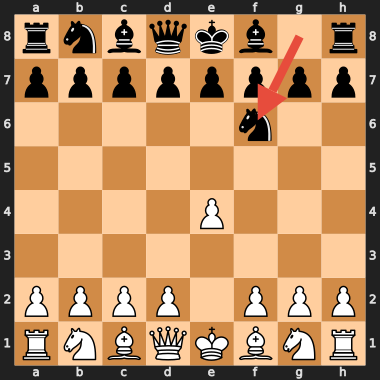

In [ ]:
from IPython.display import clear_output

def jugar_partida(tiempo_motor=3.0):
    partida = chess.Board()
    ultima_jugada = None

    while not partida.is_game_over():
        clear_output(wait=True)
        flechas = [chess.svg.Arrow(ultima_jugada.from_square, ultima_jugada.to_square, color="#e74c3c")] if ultima_jugada else []
        display(SVG(chess.svg.board(partida, arrows=flechas, size=380)))

        if partida.turn == chess.WHITE:
            entrada = input("Tu jugada (ej. e4, Nf3, O-O) o 'salir': ").strip()
            if entrada.lower() == "salir":
                print("Partida finalizada por el usuario.")
                return
            try:
                # Intenta leer notación algebraica (e4, Nf3) y si falla, UCI (e2e4)
                try:
                    jugada = partida.parse_san(entrada)
                except ValueError:
                    jugada = chess.Move.from_uci(entrada)
                    if jugada not in partida.legal_moves:
                        raise ValueError

                partida.push(jugada)
                ultima_jugada = jugada
            except ValueError:
                print(f"Jugada inválida: '{entrada}'. Intenta de nuevo.")
                time.sleep(1.5)
        else:
            print("El motor está calculando...")
            jugada_motor = buscar_con_tiempo(partida, tiempo_maximo=tiempo_motor, profundidad_max=6)
            partida.push(jugada_motor)
            ultima_jugada = jugada_motor
            time.sleep(0.5)

    clear_output(wait=True)
    display(SVG(chess.svg.board(partida, size=380)))
    print("Resultado final:", partida.result(), "| Motivo:", partida.outcome().termination.name)

# Iniciar partida (el motor tendrá 3 segundos por jugada)
jugar_partida(tiempo_motor=3.0)